# 04 — Panchang features

## Purpose

This notebook constructs the five Panchang feature groups used in our photovoltaic forecasting study:

- **Tithi:** position in the Moon–Sun phase cycle;
- **Paksha:** waxing or waning lunar half-cycle;
- **Karana:** half-Tithi category;
- **Nakshatra:** sector of the Moon's sidereal longitude;
- **Yoga:** sector of the sum of the Sun's and Moon's sidereal longitudes.

We calculate these categories from the same Sun–Moon astronomical positions used for the continuous lunar features in Notebook 03. We then encode the five groups as **97 categorical indicator variables**, the additional predictors in F4.

## 1. Load the astronomical inputs

We use the 5-minute SOLETE timeline in UTC and the JPL DE440s ephemeris. Each timestamp is represented astronomically two minutes after the recorded row time, following the convention established in Notebook 03.

The Sun's and Moon's apparent tropical ecliptic longitudes are calculated in batches. All results retain their corresponding SOLETE row timestamps.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (
        directory
        for directory in [Path.cwd(), *Path.cwd().parents]
        if (directory / "solete_dataset" / "SOLETE_Pombo_5min.h5").is_file()
        and (directory / "src" / "vedic_calendar.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the SOLETE project.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_solete
from src.astronomy_features import (
    build_lunar_f3_features,
    load_jpl_ephemeris,
    moon_sun_phase_angle_deg,
    solete_astronomy_reference_times,
    tropical_longitudes_for_solete,
)
from src.vedic_calendar import (
    lahiri_ayanamsha_for_utc_times,
    sidereal_longitude_from_tropical,
    tithi_number_from_phase,
    karana_slot_from_phase,
    yoga_angle_from_tropical_longitudes,
    build_panchang_f4_raw,
)
from src.feature_families import (
    RAW_PANCHANG_COLUMNS,
    PANCHANG_GROUP_SIZES,
    PANCHANG_INDICATOR_COUNT,
    encode_panchang_fixed_vocabulary,
    panchang_group_columns,
)

source = load_solete(
    PROJECT_ROOT / "solete_dataset" / "SOLETE_Pombo_5min.h5"
).sort_index()
timestamps = pd.DatetimeIndex(source.index)
assert timestamps.is_unique and timestamps.is_monotonic_increasing
assert len(timestamps) == 131617

reference_times = solete_astronomy_reference_times(timestamps)
ephemeris = load_jpl_ephemeris(PROJECT_ROOT / "ephemeris" / "de440s.bsp")

parts = []
for start in range(0, len(timestamps), 8192):
    batch = timestamps[start:start + 8192]
    parts.append(tropical_longitudes_for_solete(batch, ephemeris))
longitudes = pd.concat(parts)

assert longitudes.index.equals(timestamps)
assert longitudes.shape == (len(timestamps), 2)
assert np.isfinite(longitudes.to_numpy()).all()
assert ((longitudes >= 0) & (longitudes < 360)).all().all()

print("Astronomical timestamps:", len(longitudes))
display(longitudes.head(3).round(3))

Astronomical timestamps: 131617


,sun_tropical_longitude_deg,moon_tropical_longitude_deg
Timestamp,,
2018-06-01 00:00:00+00:00,70.473,277.275
2018-06-01 00:05:00+00:00,70.476,277.316
2018-06-01 00:10:00+00:00,70.479,277.358


## 2. Calculate the Moon–Sun phase

The Moon–Sun phase angle is the Moon's tropical longitude minus the Sun's tropical longitude, wrapped into a full circle.

\[
\phi=(\lambda_{\mathrm{Moon}}-\lambda_{\mathrm{Sun}})\bmod 360^\circ
\]

Tithi uses 30 sectors of 12° each. Karana uses 60 sectors of 6° each. Paksha divides the 30 Tithi positions into two groups of 15.

We compare the phase angle with the continuous sine and cosine representation from F3 at selected timestamps.

In [2]:
phase = moon_sun_phase_angle_deg(
    longitudes["sun_tropical_longitude_deg"],
    longitudes["moon_tropical_longitude_deg"],
)
assert phase.between(0, 360, inclusive="left").all()

sample_positions = np.linspace(0, len(timestamps) - 1, 7, dtype=int)
sample_times = timestamps[sample_positions]
sample_f3 = build_lunar_f3_features(sample_times, ephemeris)
np.testing.assert_allclose(
    np.sin(np.deg2rad(phase.loc[sample_times])),
    sample_f3["moon_phase_sin"],
    rtol=0, atol=1e-10,
)
np.testing.assert_allclose(
    np.cos(np.deg2rad(phase.loc[sample_times])),
    sample_f3["moon_phase_cos"],
    rtol=0, atol=1e-10,
)

phase_check = pd.DataFrame({
    "phase_angle_deg": phase.loc[sample_times],
    "tithi_number": tithi_number_from_phase(phase.loc[sample_times]),
    "karana_slot": karana_slot_from_phase(phase.loc[sample_times]),
})
display(phase_check.round(3))

,phase_angle_deg,tithi_number,karana_slot
Timestamp,,,
2018-06-01 00:00:00+00:00,206.802,18,35
2018-08-16 04:00:00+00:00,64.018,6,11
2018-10-31 08:00:00+00:00,265.289,23,45
2019-01-15 12:00:00+00:00,104.366,9,18
2019-04-01 16:00:00+00:00,318.970,27,54
2019-06-16 20:00:00+00:00,173.787,15,29
2019-09-01 00:00:00+00:00,22.280,2,4


## 3. Define the sidereal reference for Nakshatra and Yoga

Nakshatra and Yoga require a sidereal longitude. We use the **standard Lahiri ayanamsha**, calculated with Swiss Ephemeris using the `FLG_NONUT` convention established in the project.

For a tropical longitude \(\lambda\) and ayanamsha \(A\):

\[
\lambda_{\mathrm{sidereal}}=(\lambda-A)\bmod 360^\circ
\]

The Moon's sidereal longitude determines Nakshatra. The sum of the Sun's and Moon's sidereal longitudes determines Yoga. We record both underlying continuous angles to make their relationship with the categorical representation clear.

In [3]:
ayanamsha = pd.Series(
    lahiri_ayanamsha_for_utc_times(reference_times),
    index=timestamps,
    name="lahiri_ayanamsha_deg",
)
moon_sidereal = sidereal_longitude_from_tropical(
    longitudes["moon_tropical_longitude_deg"], ayanamsha
)
yoga_angle = yoga_angle_from_tropical_longitudes(
    longitudes["sun_tropical_longitude_deg"],
    longitudes["moon_tropical_longitude_deg"],
    ayanamsha,
)

assert ayanamsha.between(0, 360, inclusive="left").all()
assert moon_sidereal.between(0, 360, inclusive="left").all()
assert yoga_angle.between(0, 360, inclusive="left").all()

sidereal_summary = pd.DataFrame({
    "lahiri_ayanamsha_deg": ayanamsha,
    "moon_sidereal_longitude_deg": moon_sidereal,
    "yoga_angle_deg": yoga_angle,
})
print("Sidereal angle examples:")
display(sidereal_summary.loc[sample_times].round(3))

Sidereal angle examples:


,lahiri_ayanamsha_deg,moon_sidereal_longitude_deg,yoga_angle_deg
Timestamp,,,
2018-06-01 00:00:00+00:00,24.114,253.161,299.519
2018-08-16 04:00:00+00:00,24.117,183.161,302.304
2018-10-31 08:00:00+00:00,24.120,99.010,292.731
2019-01-15 12:00:00+00:00,24.123,15.282,286.197
2019-04-01 16:00:00+00:00,24.126,306.481,293.992
2019-06-16 20:00:00+00:00,24.129,235.051,296.315
2019-09-01 00:00:00+00:00,24.132,156.436,290.592


## 4. Calculate the five Panchang categories

The categories follow their fixed astronomical definitions:

| Panchang group | Calculation | Possible values |
|---|---|---:|
| Tithi | Moon–Sun phase in 12° sectors | 30 |
| Paksha | First or second half of the Tithi cycle | 2 |
| Karana | Moon–Sun phase in 6° sectors, mapped to traditional Karana names | 11 |
| Nakshatra | Sidereal lunar longitude in 27 equal sectors | 27 |
| Yoga | Sum of sidereal solar and lunar longitudes in 27 equal sectors | 27 |

We use the fixed category definitions from the project's Panchang implementation.

In [4]:
raw_categories = build_panchang_f4_raw(
    longitudes["sun_tropical_longitude_deg"],
    longitudes["moon_tropical_longitude_deg"],
    ayanamsha,
)
rename = {
    "tithi": "valid_tithi",
    "paksha": "valid_paksha",
    "karana": "valid_karana",
    "nakshatra": "valid_nakshatra",
    "yoga": "valid_yoga",
}
panchang = raw_categories.rename(columns=rename).loc[:, list(RAW_PANCHANG_COLUMNS)]

assert panchang.index.equals(timestamps)
assert panchang.shape == (len(timestamps), 5)
assert panchang.notna().all().all()
assert panchang["valid_tithi"].astype(int).between(1, 30).all()

print("Calculated Panchang categories:")
display(panchang.head(8))
print("Distinct observed categories in SOLETE:")
display(panchang.nunique().rename("distinct_values").to_frame())

Calculated Panchang categories:


,valid_tithi,valid_paksha,valid_karana,valid_nakshatra,valid_yoga
Timestamp,,,,,
2018-06-01 00:00:00+00:00,18,Krishna,Vanija,Mula,Shubha
2018-06-01 00:05:00+00:00,18,Krishna,Vanija,Mula,Shubha
2018-06-01 00:10:00+00:00,18,Krishna,Vanija,Mula,Shubha
2018-06-01 00:15:00+00:00,18,Krishna,Vanija,Mula,Shubha
2018-06-01 00:20:00+00:00,18,Krishna,Vanija,Mula,Shubha
2018-06-01 00:25:00+00:00,18,Krishna,Vanija,Purva Ashadha,Shubha
2018-06-01 00:30:00+00:00,18,Krishna,Vanija,Purva Ashadha,Shubha
2018-06-01 00:35:00+00:00,18,Krishna,Vanija,Purva Ashadha,Shubha


Distinct observed categories in SOLETE:


,distinct_values
valid_tithi,30
valid_paksha,2
valid_karana,11
valid_nakshatra,27
valid_yoga,27


## 5. Encode the Panchang groups for F4

The five groups are represented by a fixed set of indicator columns. A row contains one active indicator for each group, so each row has five active indicators altogether.

The category vocabulary has **97 columns**: 30 Tithi, 2 Paksha, 11 Karana, 27 Nakshatra, and 27 Yoga indicators. Keeping the vocabulary fixed gives the same column definitions in every forecasting split.

In [5]:
f4_indicators = encode_panchang_fixed_vocabulary(panchang)
groups = panchang_group_columns(f4_indicators.columns)

assert f4_indicators.index.equals(timestamps)
assert f4_indicators.shape == (len(timestamps), PANCHANG_INDICATOR_COUNT)
assert PANCHANG_INDICATOR_COUNT == 97
assert not f4_indicators.isna().any().any()
assert f4_indicators.isin([0, 1]).all().all()
assert f4_indicators.sum(axis=1).eq(5).all()

rows = []
for family, columns in groups.items():
    assert len(columns) == PANCHANG_GROUP_SIZES[family]
    assert f4_indicators.loc[:, list(columns)].sum(axis=1).eq(1).all()
    rows.append({"group": family.title(), "indicator_columns": len(columns)})

schema_summary = pd.DataFrame(rows)
display(schema_summary)
print("Total Panchang indicator variables:", f4_indicators.shape[1])

,group,indicator_columns
0,Tithi,30
1,Paksha,2
2,Karana,11
3,Nakshatra,27
4,Yoga,27


Total Panchang indicator variables: 97


## 6. Inspect the Panchang cycle

Tithi changes as the Moon–Sun phase progresses. The following plot shows how the phase angle and Tithi number evolve during a representative part of the SOLETE period.

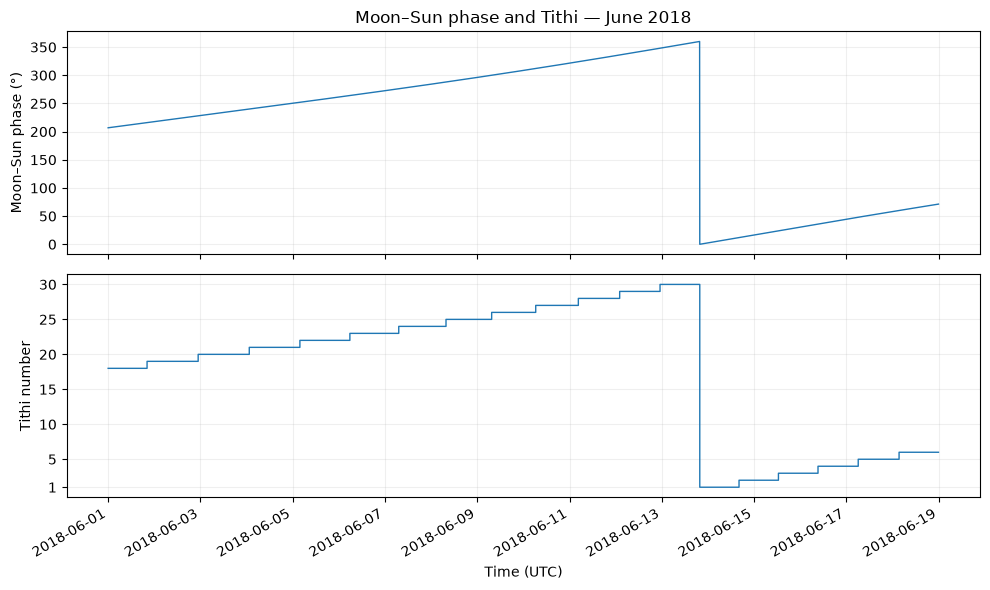

In [6]:
period = slice("2018-06-01", "2018-06-18")
phase_period = phase.loc[period]
tithi_period = panchang.loc[period, "valid_tithi"].astype(int)

fig, (ax_phase, ax_tithi) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax_phase.plot(phase_period.index, phase_period, linewidth=1)
ax_phase.set_ylabel("Moon–Sun phase (°)")
ax_phase.set_title("Moon–Sun phase and Tithi — June 2018")
ax_phase.grid(alpha=0.2)
ax_tithi.step(tithi_period.index, tithi_period, where="post", linewidth=1)
ax_tithi.set_ylabel("Tithi number")
ax_tithi.set_xlabel("Time (UTC)")
ax_tithi.set_yticks([1, 5, 10, 15, 20, 25, 30])
ax_tithi.grid(alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 7. Inspect the continuous angles underlying Nakshatra and Yoga

The F3 block includes continuous tropical astronomical geometry. Nakshatra and Yoga use sidereal angles, so we also calculate their continuous sine and cosine encodings. These four values make it possible to compare categorical sector encodings with the underlying sidereal angles in the representation analysis.

In [7]:
continuous_sidereal = pd.DataFrame({
    "moon_sidereal_sin": np.sin(np.deg2rad(moon_sidereal)),
    "moon_sidereal_cos": np.cos(np.deg2rad(moon_sidereal)),
    "yoga_angle_sin": np.sin(np.deg2rad(yoga_angle)),
    "yoga_angle_cos": np.cos(np.deg2rad(yoga_angle)),
}, index=timestamps)

assert continuous_sidereal.shape == (len(timestamps), 4)
assert continuous_sidereal.index.equals(panchang.index)
assert np.isfinite(continuous_sidereal.to_numpy()).all()
np.testing.assert_allclose(
    continuous_sidereal["moon_sidereal_sin"] ** 2
    + continuous_sidereal["moon_sidereal_cos"] ** 2,
    1.0, atol=1e-12,
)
np.testing.assert_allclose(
    continuous_sidereal["yoga_angle_sin"] ** 2
    + continuous_sidereal["yoga_angle_cos"] ** 2,
    1.0, atol=1e-12,
)

display(continuous_sidereal.loc[sample_times].round(4))

,moon_sidereal_sin,moon_sidereal_cos,yoga_angle_sin,yoga_angle_cos
Timestamp,,,,
2018-06-01 00:00:00+00:00,-0.9571,-0.2897,-0.8702,0.4927
2018-08-16 04:00:00+00:00,-0.0551,-0.9985,-0.8452,0.5344
2018-10-31 08:00:00+00:00,0.9877,-0.1566,-0.9223,0.3864
2019-01-15 12:00:00+00:00,0.2636,0.9646,-0.9603,0.2789
2019-04-01 16:00:00+00:00,-0.8041,0.5946,-0.9136,0.4066
2019-06-16 20:00:00+00:00,-0.8197,-0.5729,-0.8964,0.4433
2019-09-01 00:00:00+00:00,0.3998,-0.9166,-0.9361,0.3517


## 8. Verify the complete feature structure

F4 adds the 97 Panchang indicators to the continuous F3 predictor set. With the established 118 historical predictors in F0, the feature hierarchy contains 244 variables at F4.

The continuous sidereal variables are shown separately because they support an additional, more closely matched comparison of continuous and categorical representations.

In [8]:
feature_counts = pd.DataFrame([
    {"feature_family": "F0 — Historical", "total_variables": 118},
    {"feature_family": "F1 — Gregorian", "total_variables": 133},
    {"feature_family": "F2 — Solar", "total_variables": 138},
    {"feature_family": "F3 — Continuous lunar", "total_variables": 147},
    {"feature_family": "F4 — Panchang", "total_variables": 147 + 97},
])
display(feature_counts)

assert feature_counts["total_variables"].tolist() == [118, 133, 138, 147, 244]
assert list(panchang.columns) == list(RAW_PANCHANG_COLUMNS)
assert f4_indicators.shape[1] == 97
assert len(continuous_sidereal.columns) == 4
assert longitudes.index.equals(ayanamsha.index)
assert ayanamsha.index.equals(panchang.index)

print("NOTEBOOK 04: PANCHANG FEATURES CHECKS PASSED")

,feature_family,total_variables
0,F0 — Historical,118
1,F1 — Gregorian,133
2,F2 — Solar,138
3,F3 — Continuous lunar,147
4,F4 — Panchang,244


NOTEBOOK 04: PANCHANG FEATURES CHECKS PASSED


## What we learned

- Tithi, Paksha, and Karana are calculated from the Moon–Sun phase angle.
- Nakshatra and Yoga are calculated using the project's Lahiri sidereal convention.
- The five Panchang groups produce **97 fixed indicator variables**.
- The Panchang categories and the continuous astronomical calculations share the SOLETE UTC timeline and its two-minute astronomical reference convention.
- Four additional continuous sidereal variables describe the angles underlying Nakshatra and Yoga, providing a more closely matched continuous representation for later analysis.